In [1]:
%%writefile core.py
import numpy as np

W = 2 * np.pi / 24          # angular frequency (rad/hour)

# ---------- Model, loss, gradients (calculus) ----------
def energy(t, A, phi, M):
    return A * np.sin(W * (t - phi)) + M

def loss(t, y, A, phi, M):
    return np.mean((energy(t, A, phi, M) - y) ** 2)

def gradients(t, y, A, phi, M):
    s = np.sin(W * (t - phi))
    c = np.cos(W * (t - phi))
    err = A * s + M - y
    dA = 2 * np.mean(err * s)
    dphi = -2 * A * W * np.mean(err * c)     # chain rule
    dM = 2 * np.mean(err)
    return dA, dphi, dM

# ---------- Gradient descent ----------
def init_guess(t, y, A0=2.0):
    """Sine curves have many local minima in phi, so pick a smart starting phase."""
    M0 = np.mean(y)
    best_phi = min(np.arange(0, 24, 1.0), key=lambda p: loss(t, y, A0, p, M0))
    return A0, best_phi, M0

def fit(t, y, lr_A=0.05, lr_phi=0.5, lr_M=0.05, epochs=5000, init=None):
    A, phi, M = init if init else init_guess(t, y)
    history = []
    for _ in range(epochs):
        dA, dphi, dM = gradients(t, y, A, phi, M)
        A -= lr_A * dA
        phi -= lr_phi * dphi
        M -= lr_M * dM
        history.append(loss(t, y, A, phi, M))
    if A < 0:                       # same curve, shifted half a day
        A, phi = -A, phi + 12
    return A, phi % 24, M, history

# ---------- Insights ----------
def r2(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum((y - np.mean(y)) ** 2)

def peak_time(phi):
    return (phi + 6) % 24           # dE/dt = 0, maximum

def daytime_low(A, phi, M, lo=7.0, hi=23.0):
    """Lowest point while awake. The true minimum (phi+18) may fall at night,
    so we also check the interval endpoints."""
    grid = np.linspace(lo, hi, 400)
    return grid[np.argmin(energy(grid, A, phi, M))]

def window_integral(a, b, A, phi, M):
    """Exact integral of E(t) from a to b."""
    return M * (b - a) - (A / W) * (np.cos(W * (b - phi)) - np.cos(W * (a - phi)))

def best_window(A, phi, M, length=3.0, lo=6.0, hi=23.0):
    starts = np.arange(lo, hi - length + 0.01, 0.25)
    vals = np.array([window_integral(s, s + length, A, phi, M) for s in starts])
    i = np.argmax(vals)
    return starts[i], starts[i] + length, vals[i] / length   # avg energy in window

def sleep_debt(sleep_hours, need=8.0):
    debt = 0.0
    for s in sleep_hours:
        debt = max(0.0, debt + (need - s))
    return debt

def fmt_hour(h):
    h = h % 24
    hh, mm = int(h), int(round((h - int(h)) * 60))
    if mm == 60:
        hh, mm = hh + 1, 0
    hh %= 24
    suffix = "AM" if hh < 12 else "PM"
    return f"{(hh % 12) or 12}:{mm:02d} {suffix}"

Writing core.py


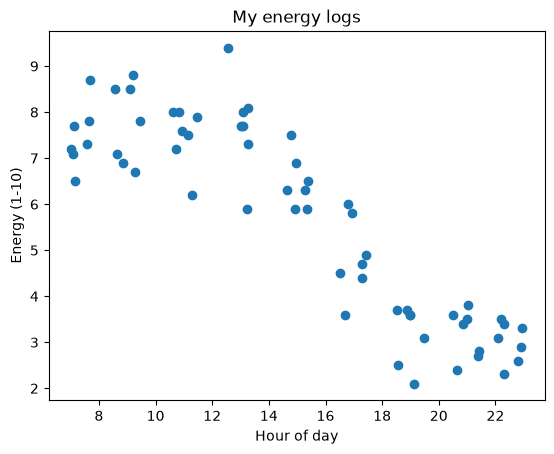

,day,hour,energy
0,1,7.08,7.1
1,1,9.22,8.8
2,1,11.48,7.9
3,1,12.57,9.4
4,1,14.77,7.5


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from core import *

np.random.seed(7)
TRUE_A, TRUE_PHI, TRUE_M = 2.5, 4.0, 5.5     # true peak = 4 + 6 = 10 AM

rows = []
for day in range(1, 8):
    for h in [7.5, 9, 11, 13, 15, 17, 19, 21, 22.5]:
        hour = h + np.random.uniform(-0.5, 0.5)
        e = energy(hour, TRUE_A, TRUE_PHI, TRUE_M) + np.random.normal(0, 0.6)
        rows.append((day, round(hour, 2), round(float(np.clip(e, 1, 10)), 1)))

df = pd.DataFrame(rows, columns=["day", "hour", "energy"])
t, y = df["hour"].values, df["energy"].values

plt.scatter(t, y); plt.xlabel("Hour of day"); plt.ylabel("Energy (1-10)")
plt.title("My energy logs"); plt.show()
df.head()

In [3]:
A, phi, M, h = 2.0, 3.0, 5.0, 1e-6
num_dA   = (loss(t,y,A+h,phi,M) - loss(t,y,A-h,phi,M)) / (2*h)
num_dphi = (loss(t,y,A,phi+h,M) - loss(t,y,A,phi-h,M)) / (2*h)
num_dM   = (loss(t,y,A,phi,M+h) - loss(t,y,A,phi,M-h)) / (2*h)

print("Analytic:", gradients(t, y, A, phi, M))
print("Numeric :", (num_dA, num_dphi, num_dM))   # should match to ~6 decimals

Analytic: (np.float64(-0.5604127602187297), np.float64(-0.451483714662199), np.float64(-1.3776243925062583))
Numeric : (np.float64(-0.5604127600866704), np.float64(-0.45148371463632486), np.float64(-1.3776243927843268))


Learned A   = 2.58  (true 2.5)
Learned phi = 4.17  (true 4.0)
Learned M   = 5.44  (true 5.5)
R² = 0.884


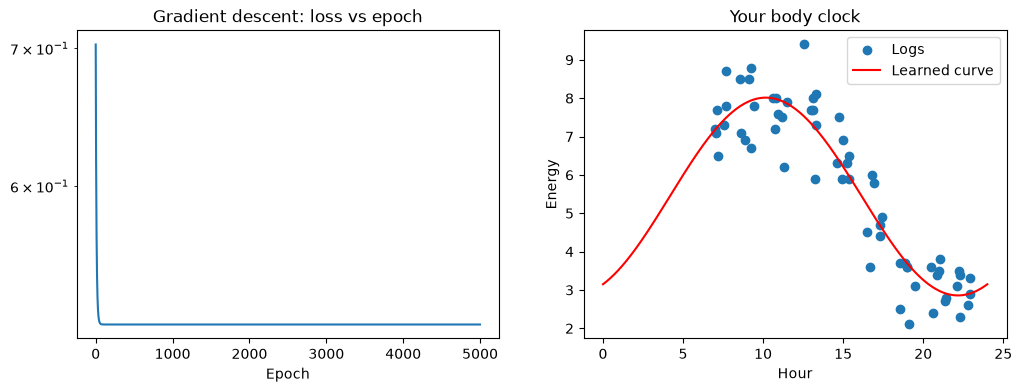

In [4]:
A_hat, phi_hat, M_hat, hist = fit(t, y)
print(f"Learned A   = {A_hat:.2f}  (true {TRUE_A})")
print(f"Learned phi = {phi_hat:.2f}  (true {TRUE_PHI})")
print(f"Learned M   = {M_hat:.2f}  (true {TRUE_M})")
print(f"R² = {r2(y, energy(t, A_hat, phi_hat, M_hat)):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist); ax[0].set_yscale("log")
ax[0].set_title("Gradient descent: loss vs epoch"); ax[0].set_xlabel("Epoch")

x = np.linspace(0, 24, 300)
ax[1].scatter(t, y, label="Logs")
ax[1].plot(x, energy(x, A_hat, phi_hat, M_hat), "r", label="Learned curve")
ax[1].set_xlabel("Hour"); ax[1].set_ylabel("Energy"); ax[1].legend()
ax[1].set_title("Your body clock"); plt.show()

In [5]:
pk = peak_time(phi_hat)
low = daytime_low(A_hat, phi_hat, M_hat)
s, e, avg = best_window(A_hat, phi_hat, M_hat, length=3)

print(f"Peak energy     : {fmt_hour(pk)}")
print(f"Daytime low     : {fmt_hour(low)}")
print(f"Best 3-h window : {fmt_hour(s)} to {fmt_hour(e)} (avg energy {avg:.1f}/10)")

sleep_log = [7, 6, 5.5, 6, 7, 5, 6.5]
print(f"Sleep debt after a week: {sleep_debt(sleep_log):.1f} hours")

Peak energy     : 10:10 AM
Daytime low     : 10:09 PM
Best 3-h window : 8:45 AM to 11:45 AM (avg energy 7.9/10)
Sleep debt after a week: 13.0 hours


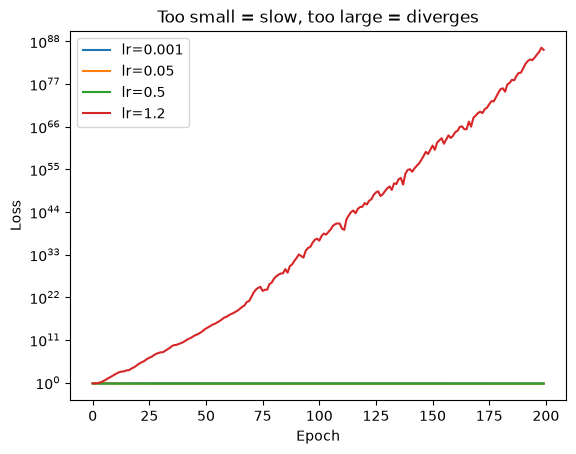

In [6]:
import warnings; warnings.filterwarnings("ignore")
for lr in [0.001, 0.05, 0.5, 1.2]:
    *_, hh = fit(t, y, lr_A=lr, lr_phi=lr, lr_M=lr, epochs=200)
    plt.plot(hh, label=f"lr={lr}")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.title("Too small = slow, too large = diverges"); plt.show()

In [8]:
try:
    # This import only works inside Google Colab
    from google.colab import files
    df.to_csv("sample_data.csv", index=False)
    files.download("core.py")
    files.download("sample_data.csv")
    print("Running on Colab: files downloaded to your computer")
except ModuleNotFoundError:
    # This runs in VS Code (local), where google.colab doesn't exist
    df.to_csv("sample_data.csv", index=False)
    print("Running locally: saved sample_data.csv in the project folder")

Running locally: saved sample_data.csv in the project folder
